  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc

Class counts:
 class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64

Accuracy: 0.9653
              precision    recall  f1-score   support

         acc       0.93      0.92      0.93       118
        good       0.70      0.84      0.76        19
       unacc       1.00      0.99      0.99       358
       vgood       0.91      0.88      0.89        24

    accuracy                           0.97       519
   macro avg       0.88      0.91      0.89       519
weighted avg       0.97      0.97      0.97       519



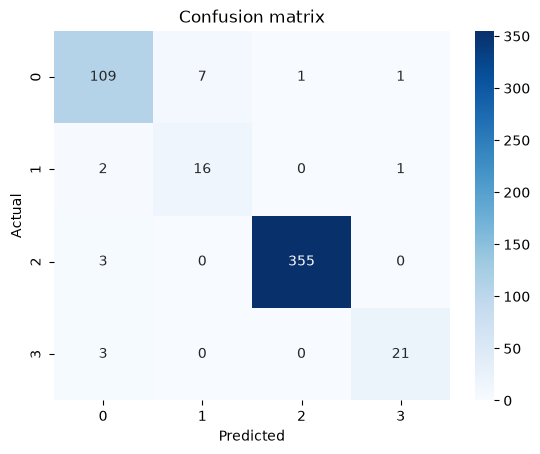

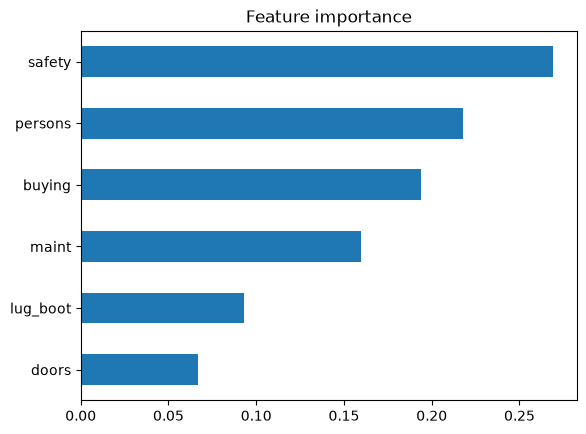

In [1]:
# Experiment 4: Ensemble Learning - Random Forest Classifier
# Aim: Predict the safety / acceptability of a car using a Random Forest Classifier.
# Dataset: car_evaluation.csv (attributes: buying, maint, doors, persons, lug_boot, safety, class)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

names = ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']
df = pd.read_csv('car_evaluation.csv', header=None, names=names)
print(df.head())
print("\nClass counts:\n", df['class'].value_counts())

for col in names[:-1]:
    df[col] = LabelEncoder().fit_transform(df[col])

X = df.drop('class', axis=1)
y = df['class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix')
plt.show()

imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind='barh')
plt.title('Feature importance')
plt.show()